# EDA: Mac

Исследование по 11 пунктам чеклиста. Данные приходят через Python-функцию из `util/loghub_systems.py`; вычисления вынесены в `util/loghub_eda.py`. Запуск: установить `requirements-eda-systems.txt`, выбрать это Python-окружение и выполнить **Restart Kernel → Run All**. Порядок ячеек самодостаточен.

Область анализа явно отмечена: полный поток и случайная выборка не смешиваются. Числа в таблицах вычисляются из данных, пропуски и ограничения сохраняются.

## 1. Происхождение данных

Лог `/var/log/system.log` с одного MacBook после семи дней использования, опубликованный авторами LogHub. Каталог указывает 117 283 строки и 16,09 MiB. Анализируем весь файл. Нет разметки аномалий, года и часового пояса; полный перечень приложений и предшествующая фильтрация не документированы.

Для календарной оси используем **условный 2000 год**, без утверждений о реальном годе или дне недели. Разные hostname могут принадлежать тому же ноутбуку. Строки без заголовка присоединяем к предыдущему корректному заголовку как продолжение. `last message repeated N times` сохраняем отдельным событием и не размножаем: точное содержание и время скрытых повторов неизвестны.

Источники: [описание Mac](https://github.com/logpai/loghub/tree/master/Mac), [каталог LogHub](https://github.com/logpai/loghub), [неизменяемая версия архива Zenodo 8196385](https://zenodo.org/records/8196385). Размер и MD5 закреплены в загрузчике по метаданным Zenodo. LogHub разрешает исследовательское/академическое использование; при распространении нужно ссылаться на LogHub и статью. Заявление LogHub «по возможности без изменений» не является гарантией отсутствия фильтрации конкретного источника.

In [1]:
import sys
import platform
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, JSON

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "util" / "loghub_systems.py").exists()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from util.loghub_systems import load_small, load_thunderbird, SOURCES
from util.loghub_eda import (
    reconstruct_events, quality_table, minute_counts, dense_minutes,
    time_summary, largest_gaps, zero_runs, distribution, drift,
    message_statistics, entity_counts, component_mentions,
    session_candidates, mine_templates, window_summary, alert_episodes,
)

SEED = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 140)
environment = {package: version(package) for package in ["numpy", "pandas", "matplotlib", "drain3", "nbclient"]}
display({"python": platform.python_version(), "executable": sys.executable, **environment})

{'python': '3.12.6',
 'executable': 'C:\\Users\\Georges\\Documents\\HSE\\year_project\\hse-ai-2026-cloud-anomaly-detection\\.venv\\Scripts\\python.exe',
 'numpy': '2.3.5',
 'pandas': '2.3.3',
 'matplotlib': '3.10.6',
 'drain3': '0.9.11',
 'nbclient': '0.10.2'}

In [2]:
NAME = "Mac"
physical, source = load_small(NAME)
prefix = physical
events_all = reconstruct_events(physical)
events = events_all.loc[events_all.parse_ok].copy()
minutes = minute_counts(events)
SCOPE = "все физические строки и восстановленные события полного файла"
assert len(physical) == source["physical_lines"]
assert events_all.physical_line_count.sum() == len(physical)
assert minutes["count"].sum() == events.timestamp.notna().sum()
dense = dense_minutes(minutes)
display({"analysis_scope": SCOPE, "source": source["url"], "MD5 archive": source["archive_md5"], "SHA256 raw": source["sha256_raw"]})

{'analysis_scope': 'все физические строки и восстановленные события полного файла',
 'source': 'https://zenodo.org/records/8196385/files/Mac.tar.gz?download=1',
 'MD5 archive': 'e5d0558b6ec661c739e77c7ff1b71498',
 'SHA256 raw': '1508444de3c5ae538db936e5d52b41551e2a76cf38904886a0eed570e893de17'}

## 2. Физическая организация

Архив tar.gz содержит текстовый `.log`. Читаем бинарные строки по LF, отдельно считаем CRLF, проверяем строгое декодирование UTF-8. При ошибке сохраняем строку с replacement-символом и учитываем ошибку; строки не исчезают молча. Отсутствие финального LF само по себе не доказывает обрыв. Наличие даты и PID зависит от источника.

ZooKeeper: `YYYY-MM-DD HH:MM:SS,mmm - LEVEL [context:Class@line] - message`. OpenSSH/Mac: `Mon day HH:MM:SS host process[pid]: message`, при этом Mac допускает пробелы в имени процесса и строки продолжения.

In [3]:
display(pd.Series({key: source.get(key, 0) for key in ["member", "member_bytes", "physical_lines", "bytes", "crlf", "lf", "no_final_lf", "invalid_utf8_lines"]}, name="source_fact"))
display(physical.dtypes.astype(str).to_frame("parsed_dtype"))

member                 Mac.log
member_bytes          16879552
physical_lines          117283
bytes                 16879552
crlf                    117283
lf                           0
no_final_lf                  0
invalid_utf8_lines           0
Name: source_fact, dtype: object

,parsed_dtype
line_no,int64
raw,object
parse_ok,bool
header_start,bool
message,object
host,object
component,object
level,object
pid,object
label,object


## 3. Первичный осмотр и качество

Ниже — **100 первых и 100 случайных строк целиком**, с номерами в исходном файле. Случайный отбор детерминирован. Дубли считаем по полному тексту, включая заголовок; это наблюдение, а не команда удалить записи. Выбросы и ошибки парсинга показываем отдельно.

В таблице различаются физические строки и события. Наличие многострочных событий проверяется после восстановления; это эвристика по границам заголовков.

In [4]:
with pd.option_context("display.max_rows", 100, "display.max_colwidth", None):
    display(prefix[["line_no", "raw"]].head(100))
    display(physical[["line_no", "raw"]].sample(n=min(100, len(physical)), random_state=SEED).sort_values("line_no"))

,line_no,raw
0,1,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: AppleThunderboltNHIType2::prePCIWake - power up complete - took 2 us
1,2,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: AppleThunderboltGenericHAL::earlyWake - complete - took 0 milliseconds
2,3,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: AirPort: Link Down on awdl0. Reason 1 (Unspecified).
3,4,"Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: ARPT: 620651.021206: wl0: wl_update_tcpkeep_seq: Original Seq: 2477329075, Ack: 1662858865, Win size: 4096"
4,5,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: Bluetooth -- LE is supported - Disable LE meta event
5,6,"Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: ARPT: 620651.021235: wl0: wl_update_tcpkeep_seq: Updated seq/ack/win from UserClient Seq 2477329075, Ack 1662858865, Win size 278"
6,7,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: ARPT: 620651.021264: wl0: leaveModulePoweredForOffloads: Wi-Fi will stay on.
7,8,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: ARPT: 620651.047545: AirPort_Brcm43xx::platformWoWEnable: WWEN[enable]
8,9,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: ARPT: 620651.048430: AirPort_Brcm43xx::syncPowerState: WWEN[enabled]
9,10,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: IOThunderboltSwitch<0>(0x0)::listenerCallback - Thunderbolt HPD packet for route = 0x0 port = 11 unplug = 0


,line_no,raw
646,647,"Jul 1 09:12:29 calvisitor-10-105-160-95 com.apple.cts[258]: com.apple.EscrowSecurityAlert.daily: scheduler_evaluate_activity told me to run this job; however, but the start time isn't for 13962 seconds. Ignoring."
1199,1200,Jul 1 09:21:52 calvisitor-10-105-160-95 kernel[0]: en0: channel changed to 1
2854,2855,"Jul 1 09:34:52 calvisitor-10-105-160-95 com.apple.cts[43]: com.apple.CacheDelete.daily: scheduler_evaluate_activity told me to run this job; however, but the start time isn't for 12531 seconds. Ignoring."
3030,3031,"Jul 1 09:36:29 calvisitor-10-105-160-95 com.apple.cts[258]: com.apple.Safari.SafeBrowsing.Update: scheduler_evaluate_activity told me to run this job; however, but the start time isn't for 1583 seconds. Ignoring."
5428,5429,Jul 1 11:41:25 authorMacBook-Pro mDNSResponder[91]: mDNS_RegisterInterface: Frequent transitions for interface awdl0 (FE80:0000:0000:0000:D8A5:90FF:FEF5:7FFF)
6075,6076,Jul 1 11:46:16 authorMacBook-Pro corecaptured[31437]: CCFile::captureLog
6235,6236,"Jul 1 11:47:56 calvisitor-10-105-160-95 kernel[0]: ARPT: 626378.569393: wl0: wl_update_tcpkeep_seq: Original Seq: 2639666838, Ack: 2188101151, Win size: 4096"
6657,6658,Jul 1 11:51:02 calvisitor-10-105-160-95 kernel[0]: IOThunderboltSwitch<0>(0x0)::listenerCallback - Thunderbolt HPD packet for route = 0x0 port = 12 unplug = 0
7095,7096,Jul 1 11:55:14 authorMacBook-Pro mDNSResponder[91]: mDNS_DeregisterInterface: Frequent transitions for interface en0 (2607:F140:6000:0008:C6B3:01FF:FECD:467F)
8777,8778,Jul 1 14:14:51 calvisitor-10-105-160-95 kernel[0]: IOThunderboltSwitch<0>(0x0)::listenerCallback - Thunderbolt HPD packet for route = 0x0 port = 12 unplug = 0


In [5]:
quality = quality_table(physical, source, events_all)
display(quality.to_frame())
display(physical.loc[~physical.parse_ok, ["line_no", "raw"]].head(15))
display(events.loc[events.physical_line_count.gt(1), ["line_no", "physical_line_count", "message"]].head(5))
display(physical.loc[physical.raw.duplicated(keep=False), ["line_no", "raw"]].head(10))

,value
source_physical_lines (full),1.172830e+05
published_lines (reference),1.172830e+05
source_bytes (full),1.687955e+07
analyzed_physical_lines,1.172830e+05
analyzed_events,1.071450e+05
mean_line_characters,1.418291e+02
blank_lines,5.480000e+02
duplicate_raw_lines_beyond_first,2.144700e+04
unparsed_physical_lines,1.013800e+04
without_header_start,1.013800e+04


,line_no,raw
4830,4831,\t(
4831,4832,"\t ""<NSAutoresizingMaskLayoutConstraint:0x7f9d64c107d0 h=-&- v=-&- V:[NSScrollView:0x7f9d77a377c0]-(11)-| (Names: '|':NSView:0x7f9d..."
4832,4833,"\t ""<NSAutoresizingMaskLayoutConstraint:0x7f9d64c10820 h=-&- v=-&- V:|-(45)-[NSScrollView:0x7f9d77a377c0] (Names: '|':NSView:0x7f9d..."
4833,4834,"\t ""<NSAutoresizingMaskLayoutConstraint:0x7f9d64c1ad30 h=-&- v=--& V:[NSView:0x7f9d7bb25b30(0)]>"","
4834,4835,"\t ""<NSAutoresizingMaskLayoutConstraint:0x7f9d64c3ae50 h=-&- v=-&- V:|-(0)-[NSView:0x7f9d5deb2520] (Names: '|':NSView:0x7f9d7bb25b3..."
4835,4836,"\t ""<NSAutoresizingMaskLayoutConstraint:0x7f9d64c3ae00 h=-&- v=-&- V:[NSView:0x7f9d5deb2520]-(0)-| (Names: '|':NSView:0x7f9d7bb25b3..."
4836,4837,\t)
4837,4838,\t
4838,4839,\tWill attempt to recover by breaking constraint
4839,4840,\t<NSAutoresizingMaskLayoutConstraint:0x7f9d64c10820 h=-&- v=-&- V:|-(45)-[NSScrollView:0x7f9d77a377c0] (Names: '|':NSView:0x7f9d5deb2...


,line_no,physical_line_count,message
4829,4830,13,"Unable to simultaneously satisfy constraints:\n\t(\n\t ""<NSAutoresizingMaskLayoutConstraint:0x7f9d64c107d0 h=-&- v=-&- V:[NSScrollVie..."
8226,8239,2,<IMMacNotificationCenterManager: 0x7fdcc9d16380>: Updating enabled: NO (Topics: (\n\t))
8227,8241,2,<IMMacNotificationCenterManager: 0x7ff1b2d17980>: Updating enabled: NO (Topics: (\n\t))
8231,8246,2,<IMMacNotificationCenterManager: 0x7ff1b2e00ba0>: Updating enabled: NO (Topics: (\n\t))
9285,9301,3,"hostControllerOnline - Number of Paired devices = 1, List of Paired devices = (\n\t ""84-41-67-32-db-e1""\n\t)"


,line_no,raw
9,10,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: IOThunderboltSwitch<0>(0x0)::listenerCallback - Thunderbolt HPD packet for route = 0...
10,11,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: IOThunderboltSwitch<0>(0x0)::listenerCallback - Thunderbolt HPD packet for route = 0...
11,12,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: AppleCamIn::systemWakeCall - messageType = 0xE0000340
15,16,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: AppleCamIn::systemWakeCall - messageType = 0xE0000340
21,22,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: IOThunderboltSwitch<0>(0x0)::listenerCallback - Thunderbolt HPD packet for route = 0...
22,23,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: IOThunderboltSwitch<0>(0x0)::listenerCallback - Thunderbolt HPD packet for route = 0...
25,26,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: en0: channel changed to 1
30,31,Jul 1 09:00:55 calvisitor-10-105-160-95 kernel[0]: en0: channel changed to 1
59,60,Jul 1 09:00:56 authorMacBook-Pro symptomsd[215]: __73-[NetworkAnalyticsEngine observeValueForKeyPath:ofObject:change:context:]_block_in...
60,61,Jul 1 09:00:56 authorMacBook-Pro Dropbox[24019]: [0701/090056:WARNING:dns_config_service_posix.cc(306)] Failed to read DnsConfig.


## 4. Время

Порядок в файле и хронологический порядок проверяются отдельно. Повторяющиеся timestamps допустимы для одновременных событий. Пустые интервалы означают отсутствие записей в опубликованном файле; без метрик доступности нельзя отличить простой системы от потери логов.

В ZooKeeper разрешение 1 ms; OpenSSH и Mac — 1 s. Часовой пояс не указан, поэтому timestamps остаются timezone-naive. Для syslog годы синтетические, переход года учитывается. Мы не утверждаем, что все машины использовали один пояс.

In [6]:
display(time_summary(events).to_frame("analyzed_events"))
display(zero_runs(minutes).head(10))

display(largest_gaps(events))

,analyzed_events
valid_timestamp_events,107145
missing_timestamps,0
first_in_file,2000-07-01 09:00:55
last_in_file,2000-07-08 08:52:05
chronological_min,2000-07-01 08:58:36
chronological_max,2000-07-08 08:52:05
span,6 days 23:53:29
backsteps_file_order,560
repeated_timestamps_beyond_first,89246
fractional_second_events,0


,start,end_exclusive,minutes
83,2000-07-02 02:47:00,2000-07-02 10:11:00,444
434,2000-07-05 04:14:00,2000-07-05 10:31:00,377
37,2000-07-01 15:07:00,2000-07-01 19:43:00,276
489,2000-07-06 05:05:00,2000-07-06 08:32:00,207
80,2000-07-01 23:47:00,2000-07-02 02:18:00,151
650,2000-07-07 12:32:00,2000-07-07 13:38:00,66
702,2000-07-08 01:00:00,2000-07-08 01:51:00,51
698,2000-07-07 23:40:00,2000-07-08 00:30:00,50
486,2000-07-06 03:14:00,2000-07-06 03:53:00,39
484,2000-07-06 01:53:00,2000-07-06 02:32:00,39


,from,to,gap_seconds
1911,2000-07-02 02:46:53,2000-07-02 10:11:12,26659.0
10694,2000-07-05 04:13:23,2000-07-05 10:31:18,22675.0
1214,2000-07-01 15:06:41,2000-07-01 19:43:22,16601.0
12228,2000-07-06 05:04:38,2000-07-06 08:32:37,12479.0
1878,2000-07-01 23:46:12,2000-07-02 02:18:38,9146.0
15680,2000-07-07 12:31:08,2000-07-07 13:38:15,4027.0
17240,2000-07-08 00:59:16,2000-07-08 01:51:46,3150.0
17198,2000-07-07 23:39:27,2000-07-08 00:30:38,3071.0
11729,2000-07-05 17:39:51,2000-07-05 18:19:59,2408.0
11273,2000-07-05 14:16:28,2000-07-05 14:56:08,2380.0


## 5. Объём, производители и изменение распределений

Интенсивность считается на полном временном диапазоне с нулевыми минутами. Крайние сутки/часы могут быть неполными. Средние по часу суток — разведочный профиль, а не доказанная сезонность: для этого нужны несколько сопоставимых циклов и модель нагрузки.

Уровни severity используем только из явного поля. Слова `error`, `failed` и категории alert не превращаем в INFO/ERROR. `<missing>` означает, что поле отсутствует. Для ZooKeeper host недоступен; для Mac разные имена не доказывают несколько физических машин. TVD — половина суммы модулей разностей долей между первой и второй половинами периода (0 = одинаковые распределения, 1 = непересекающиеся).

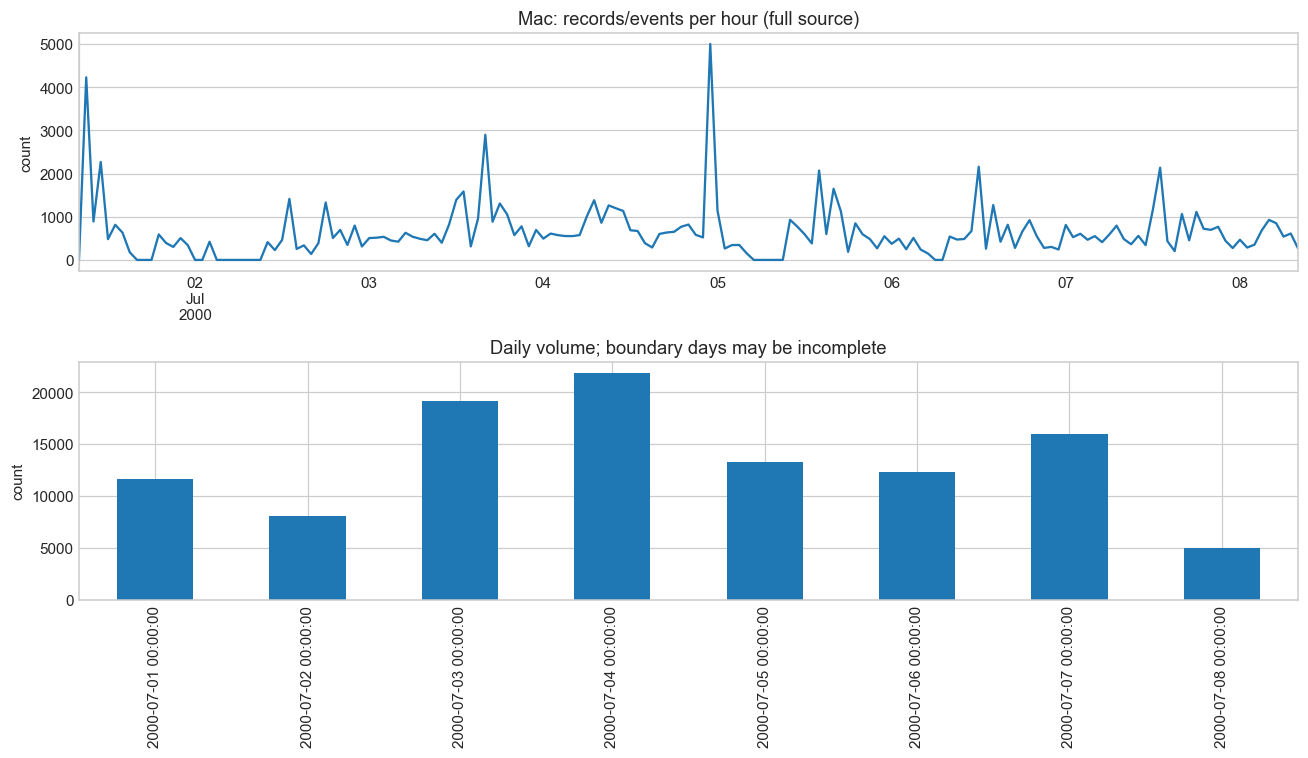

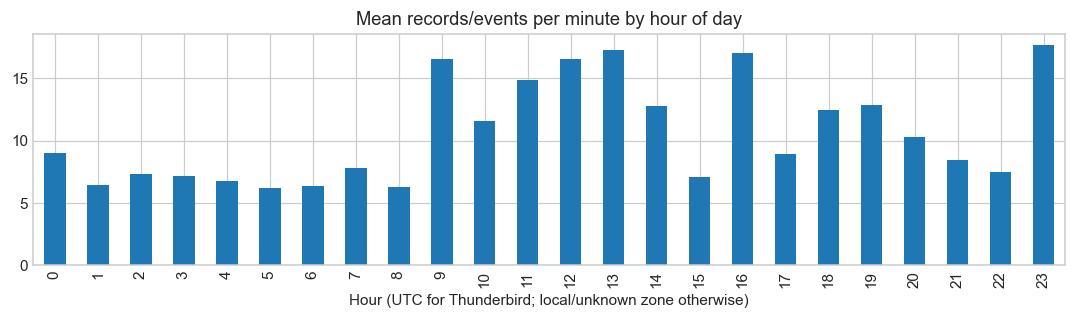

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
dense["count"].resample("1h").sum().plot(ax=axes[0], title=f"{NAME}: records/events per hour (full source)")
dense["count"].resample("1D").sum().plot.bar(ax=axes[1], title="Daily volume; boundary days may be incomplete")
axes[1].set_xticks(axes[1].get_xticks()[::max(1, len(dense.resample("1D").sum()) // 12)])
for ax in axes:
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(10, 3))
dense.groupby(dense.index.hour)["count"].mean().plot.bar(ax=ax, title="Mean records/events per minute by hour of day")
ax.set_xlabel("Hour (UTC for Thunderbird; local/unknown zone otherwise)")
plt.tight_layout()
plt.show()

In [8]:
for column in ["component", "host", "level"]:
    display(Markdown(f"**{column}: частоты и изменение долей ({SCOPE})**"))
    display(distribution(events, column).head(12))
    changes, tvd = drift(events, column)
    display({"total_variation_distance": tvd})
    display(changes.head(8))

**component: частоты и изменение долей (все физические строки и восстановленные события полного файла)**

,count,fraction
component,,
kernel,41181,0.384348
corecaptured,8585,0.080125
com.apple.cts,7743,0.072267
syslog_repeat,4377,0.040851
Microsoft Word,4067,0.037958
com.apple.WebKit.WebContent,3417,0.031891
QQ,3202,0.029885
com.apple.AddressBook.InternetAccountsBridge,3177,0.029651
WindowServer,2294,0.021410


{'total_variation_distance': 0.18848042085492434}

period,first_half,second_half,delta
component,,,
Microsoft Word,0.000606,0.076583,0.075977
kernel,0.409748,0.358083,-0.051666
com.apple.cts,0.094492,0.049283,-0.045209
corecaptured,0.060878,0.100028,0.039151
com.apple.WebKit.WebContent,0.048853,0.014352,-0.034500
com.apple.AddressBook.InternetAccountsBridge,0.036314,0.022762,-0.013551
networkd,0.014357,0.025781,0.011424
sharingd,0.018597,0.008011,-0.010586


**host: частоты и изменение долей (все физические строки и восстановленные события полного файла)**

,count,fraction
host,,
authorMacBook-Pro,29339,0.273825
calvisitor-10-105-162-105,16825,0.157030
calvisitor-10-105-162-178,11975,0.111764
calvisitor-10-105-163-202,7587,0.070811
calvisitor-10-105-160-95,6996,0.065295
airbears2-10-142-110-255,4522,0.042204
<missing>,4377,0.040851
calvisitor-10-105-160-85,4179,0.039003
calvisitor-10-105-160-237,2821,0.026329


... (2 outputs left out)

**level: частоты и изменение долей (все физические строки и восстановленные события полного файла)**

,count,fraction
level,,
<missing>,107145,1.0


{'total_variation_distance': 0.0}

period,first_half,second_half,delta
level,,,
<missing>,1.0,1.0,0.0


## 6. Сообщения

Длины измеряем в символах Unicode. Выброс — выше Q3 + 1,5×IQR, это статистическое правило, а не метка аномалии. Слова: латинские буквенные токены длиной от двух символов, lowercase, без stop-word фильтра. Биграммы не пересекают границы сообщений. Редкие токены и сообщения сохраняют параметры, поэтому их редкость ещё не означает новое поведение. Ссылки на компоненты ищем среди 20 наиболее активных имён; совпадение текста не устанавливает сетевую зависимость.

,message_characters
count,107145.000000
mean,99.446778
std,119.122104
min,1.000000
1%,18.000000
50%,76.000000
90%,153.000000
95%,237.000000
99%,434.000000
max,5436.000000


{'IQR_cutoff': 212.0, 'outlier_events': 6158}

,line_no,message_length,message
76875,81733,5436,"-[NETAWDManager reportStats:metricID:] AWDServerConnection newMetricContainerWithIdentifier failed for metric 2686985, server 0x7faf9371..."
37735,40002,5429,"-[NETAWDManager reportStats:metricID:] AWDServerConnection newMetricContainerWithIdentifier failed for metric 2686985, server 0x7faf9371..."
14658,15349,5419,"-[NETAWDManager reportStats:metricID:] AWDServerConnection newMetricContainerWithIdentifier failed for metric 2686985, server 0x7faf9371..."
99997,109594,5408,"-[NETAWDManager reportStats:metricID:] AWDServerConnection newMetricContainerWithIdentifier failed for metric 2686985, server 0x7faf9371..."
10482,10806,4143,[21:08:39.395] CMSampleBufferCallForEachSample signalled err=1 (err) ([aborting loop early due to error from callback]) at /Library/Cach...


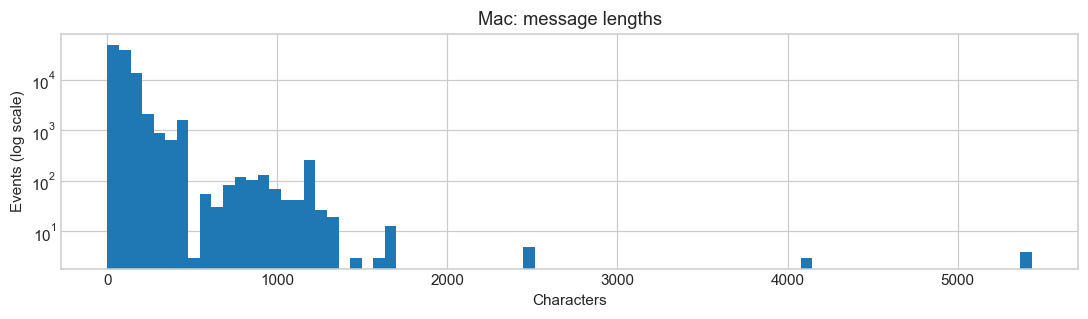

**words: самые частые и редкие**

,token,count
0,com,24352
1,apple,21295
2,to,20544
3,for,17175
4,the,14532
5,arpt,12377
6,time,11638
7,run,11402
8,error,10373
9,this,9261


,token,count
2963,aacb,1
2964,aacf,1
2965,aadfcca,1
2966,aaee,1
2967,abdd,1
2968,abfff,1
2969,acacd,1
2970,acbb,1
2971,acbdcb,1
2972,acbfed,1


**bigrams: самые частые и редкие**

,token,count
0,com apple,20705
1,this job,7743
2,for seconds,7738
3,to run,7730
4,but the,7711
5,however but,7711
6,isn for,7711
7,job however,7711
8,me to,7711
9,run this,7711


,token,count
7086,aa ad,1
7087,aa db,1
7088,aa ebc,1
7089,aa ecebb,1
7090,aa error,1
7091,aa fa,1
7092,aa fff,1
7093,aa is,1
7094,aa javascriptcore,1
7095,aa path,1


... (2 outputs left out)

,count
message,
--- last message repeated 1 time ---,3486
AppleCamIn::systemWakeCall - messageType = 0xE0000340,2397
send_datagram_available_ping: pid 445 failed to act on a ping it dequeued before timing out.,1668
CCFile::captureLogRun() Exiting CCFile::captureLogRun,1242
AppleCamIn::wakeEventHandlerThread,1064
CCFile::captureLog,968
IOThunderboltSwitch<0>(0x0)::listenerCallback - Thunderbolt HPD packet for route = 0x0 port = 11 unplug = 0,966
Received Capture Event,959
Thermal pressure state: 0 Memory pressure state: 0,931


,count
singleton_message,
"ARPT: 790708.368522: IOPMPowerSource Information: onSleep, SleepType: Normal Sleep, 'ExternalConnected': No, 'TimeRemaining': 15462,",1
"ARPT: 620651.021206: wl0: wl_update_tcpkeep_seq: Original Seq: 2477329075, Ack: 1662858865, Win size: 4096",1
"ARPT: 620651.021235: wl0: wl_update_tcpkeep_seq: Updated seq/ack/win from UserClient Seq 2477329075, Ack 1662858865, Win size 278",1
ARPT: 620651.021264: wl0: leaveModulePoweredForOffloads: Wi-Fi will stay on.,1
ARPT: 620651.047545: AirPort_Brcm43xx::platformWoWEnable: WWEN[enable],1
ARPT: 620651.048430: AirPort_Brcm43xx::syncPowerState: WWEN[enabled],1
"ARPT: 790667.802468: wl0: MDNS: 0 SRV Recs, 0 TXT Recs",1
"PM response took 4362 ms (54, powerd)",1
ARPT: 790667.809116: AirPort_Brcm43xx::powerChange: System Sleep,1


,count
message_seen_2_to_5,
com.apple.Addres(31229) deny network-outbound /private/var/run/mDNSResponder,5
**** [IOBluetoothFamily][ProcessBluetoothTransportShowsUpActionWL] -- calling IOBluetoothFamily's registerService() -- 0x5fd0 -- 0x9a00 -- 0xd800 ****,5
storeaccountd(345) deny file-write-create /Users/xpc/Library/Caches/com.apple.Safari/ProductionBag,5
XPC Activity invoked with state=2,5
hfs: mounted Recovery HD on device disk0s3,5
Logging disabled completely for device:1: /Volumes/Recovery HD,5
**** [IOBluetoothFamily][ProcessBluetoothTransportShowsUpActionWL] -- Connected to the transport successfully -- 0x5fd0 -- 0x9a00 -- 0xd800 ****,5
Sandbox: com.apple.Addres(32198) deny(1) network-outbound /private/var/run/mDNSResponder,5
--- last message repeated 8 times ---,5


,producer,mentioned_component,events
0,com.apple.cts,Safari,1595
1,com.apple.xpc.launchd,com.apple.WebKit.WebContent,925
2,com.apple.xpc.launchd,Safari,925
3,networkd,QQ,784
4,sandboxd,QQ,112
5,kernel,QQ,77
6,com.apple.WebKit.WebContent,Safari,54
7,networkd,locationd,33
8,mDNSResponder,configd,10
9,kernel,Safari,7


In [9]:
text_stats = message_statistics(events)
display(text_stats["lengths"].to_frame("message_characters"))
display({"IQR_cutoff": text_stats["outlier_cutoff_IQR"], "outlier_events": text_stats["outliers"]})
display(events.nlargest(5, "message_length")[["line_no", "message_length", "message"]])
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(events.message_length, bins=80, log=True)
ax.set(title=f"{NAME}: message lengths", xlabel="Characters", ylabel="Events (log scale)")
plt.tight_layout()
plt.show()
for kind in ["words", "bigrams"]:
    display(Markdown(f"**{kind}: самые частые и редкие**"))
    display(text_stats[kind].head(12))
    display(text_stats[kind].sort_values(["count", "token"]).head(12))
characters = text_stats["characters"].to_frame("characters")
characters["fraction"] = characters.characters / characters.characters.sum()
display(characters)
display(text_stats["frequency_bands"].to_frame("unique_message_count"))
display(text_stats["messages"].head(10).rename_axis("message").to_frame("count"))
display(text_stats["messages"].loc[lambda s: s.eq(1)].head(10).rename_axis("singleton_message").to_frame("count"))
display(text_stats["messages"].loc[lambda s: s.between(2, 5)].head(10).rename_axis("message_seen_2_to_5").to_frame("count"))
display(component_mentions(events))

## 7. Сущности и кандидаты в сессии

Регулярные выражения выделяют IPv4/IPv6, порты, UUID, пути, URL, кандидаты в хэши и устройства, явные session ID. Синтаксис IP проверяется через `ipaddress`, порты ограничены 0–65535. Даже корректная по форме последовательность может оказаться частью другого идентификатора; это не подтверждение сетевой роли сущности. Пути, хэши и устройства — **кандидаты**, а не подтверждённые типы: 32 hex-символа могут быть ID, `/10.0.0.1` — адресом, а не путём. Классы могут пересекаться; их суммы нельзя складывать как число сущностей. Ищем в сообщениях, без полей заголовка.

ZooKeeper: явный `session id 0x…`. OpenSSH: `(host, PID, сегмент активности с разрывом >30 минут)` — эвристика, PID переиспользуется и не равен ID соединения. Для Mac и Thunderbird универсальный session ID не заявляем.

In [10]:
entities, entity_examples = entity_counts(events)
display(entities)
for kind, examples in entity_examples.items():
    display(Markdown(f"**{kind}: примеры и число упоминаний**"))
    display(examples)
sessions = session_candidates(events, NAME)
display({"candidate_sessions": len(sessions)})
display(sessions.head(10))

,unique,mentions,events_with_entity
entity,,,
ipv4,272,3321,3284
ipv6,126,1746,1745
port,406,3880,3435
uuid,114,531,422
path,175,8294,6728
url,152,1994,840
hash_candidate,43,528,328
device_candidate,4,8351,7943
session_id,0,0,0


**ipv4: примеры и число упоминаний**

,value,mentions
0,10.105.162.105,302
1,10.105.160.95,260
2,119.81.102.227,240
3,10.105.162.178,224
4,103.251.128.144,146
5,10.142.110.44,132
6,10.105.163.202,118
7,123.125.50.30,94
8,1.2.8.57,79
9,10.142.110.255,67


**ipv6: примеры и число упоминаний**

,value,mentions
0,fe80::c6b3:1ff:fecd:467f,612
1,2607:f140:6000:8:c6b3:1ff:fecd:467f,444
2,fe80::d8a5:90ff:fef5:7fff,117
3,2607:f140:400:a01b:c6b3:1ff:fecd:467f,96
4,2607:f140:400:a01b:f034:7d78:dd64:fe98,63
5,2607:f140:6000:8:51cf:994c:36cb:1c56,40
6,2607:f140:400:a01b:1c57:7ef3:8f8e:5a10,31
7,2607:f140:6000:8:3065:65eb:758e:972a,27
8,2607:f140:6000:8:794a:5882:73fd:84a,17
9,2607:f140:6000:8:9cb8:f7f2:7c03:f956,16


**port: примеры и число упоминаний**

... (11 outputs left out)

**session_id: примеры и число упоминаний**

,value,mentions


{'candidate_sessions': 0}

,events,first,last,duration_seconds


## 8. Шаблоны событий

Используем [Drain3](https://github.com/logpai/Drain3), `depth=4`, `sim_th=0.4`, с масками UUID/IP/HEX/NUM. Обучаем на текстах сообщений в порядке файла, без времён и labels. Для каждого cluster ID показываем **финальный** шаблон, потому что при обучении он обобщается. Это исследовательская кластеризация, не оценка точности парсинга. Время первого/последнего наблюдения и число дней не доказывают рождение/исчезновение события вне периода наблюдения. Для Thunderbird это особенно существенно: редкий шаблон мог не попасть в выборку.

{'templates': 636, 'singleton_templates': 92}

,count,template,first,last,observed_days
template_id,,,,,
53,4377,--- last message repeated <NUM> <*> ---,2000-07-01 09:00:56,2000-07-08 08:51:39,8
483,3930,Cocoa scripting error for '<HEX>': four character codes must be four characters long.,2000-07-04 23:22:09,2000-07-04 23:22:09,1
10,2679,AppleCamIn::systemWakeCall - messageType = <HEX>,2000-07-01 09:00:55,2000-07-08 08:52:05,8
89,2660,ARPT: <NUM>.<NUM>: wl0: <*> <*> <*> <*>,2000-07-01 09:01:41,2000-07-08 08:52:03,8
19,2628,en0: <*> changed to <*>,2000-07-01 09:00:55,2000-07-08 08:51:26,8
113,2304,dnssd_clientstub ConnectToServer: connect()-> No of tries: <NUM>,2000-07-01 09:25:31,2000-07-08 08:51:46,8
116,1880,Sandbox: <*> deny(<NUM>) <*> <*>,2000-07-01 09:25:38,2000-07-08 08:51:47,8
83,1859,Thermal pressure state: <NUM> Memory pressure state: <NUM>,2000-07-01 09:01:05,2000-07-08 08:51:47,8
9,1764,IOThunderboltSwitch<<NUM>>(<HEX>)::listenerCallback - Thunderbolt HPD packet for route = <HEX> port = <NUM> unplug = <NUM>,2000-07-01 09:00:55,2000-07-08 08:51:26,8


,count,template,first,last,observed_days
template_id,,,,,
481,1,#3f4ddf17 [I:AssetCacheLocatorService.queue] found no caching servers,2000-07-04 23:13:19,2000-07-04 23:13:19,1
590,1,"(UID <NUM>) Found <NUM> plugin types, <NUM> plugins",2000-07-07 15:14:28,2000-07-07 15:14:28,1
477,1,*** -[AVAssetResourceLoadingRequest finishLoading] was sent to an instance of AVAssetResourceLoadingRequest that was already finished. I...,2000-07-04 15:45:00,2000-07-04 15:45:00,1
602,1,"*** Assertion failure in +[LUTextAccessor rangeOfTermInString:containingOffset:language:partOfSpeech:], /Library/Caches/com.apple.xbs/So...",2000-07-07 20:27:08,2000-07-07 20:27:08,1
547,1,*** WebKit discarding exception: <NSRangeException> *** -[__NSArrayM objectAtIndex:]: index <NUM> beyond bounds for empty array,2000-07-05 10:47:48,2000-07-05 10:47:48,1
556,1,+[NSFileCoordinator addFilePresenter:] could not get a sandbox extension. primaryPresentedItemURL: file:////Users/xpc/Library/Group%20Co...,2000-07-05 12:02:38,2000-07-05 12:02:38,1
579,1,-[NETPowerManager powerPolicyForTimeslot:workload:] failed to find policy for workload <NUM> timeslot <NUM> / <NUM>,2000-07-06 08:51:21,2000-07-06 08:51:21,1
536,1,-_continuousScroll is deprecated for NSScrollWheel. Please use -hasPreciseScrollingDeltas.,2000-07-05 00:21:07,2000-07-05 00:21:07,1
537,1,-deviceDeltaX is deprecated for NSScrollWheel. Please use -scrollingDeltaX.,2000-07-05 00:21:07,2000-07-05 00:21:07,1


,count,template,first,last,observed_days
template_id,,,,,
11,532,AppleThunderboltNHIType2::waitForOk2Go2Sx - intel_rp = <NUM> dlla_reporting_supported = <NUM>,2000-07-01 08:58:36,2000-07-08 08:38:00,8
1,1019,AppleThunderboltNHIType2::prePCIWake - power up complete - took <NUM> us,2000-07-01 09:00:55,2000-07-08 08:51:26,8
25,757,AirPort: Link Up on <*>,2000-07-01 09:00:55,2000-07-08 08:51:26,8
21,448,en0: <NUM>.11d country code set to <*>,2000-07-01 09:00:55,2000-07-08 07:31:25,8
29,950,"ARPT: <NUM>.<NUM>: IOPMPowerSource Information: <*> SleepType: Normal Sleep, 'ExternalConnected': <*> 'TimeRemaining': <NUM>,",2000-07-01 09:00:55,2000-07-08 08:52:05,8
4,442,"ARPT: <NUM>.<NUM>: wl0: wl_update_tcpkeep_seq: Original Seq: <NUM>, Ack: <NUM>, Win size: <NUM>",2000-07-01 09:00:55,2000-07-08 08:51:26,8
6,440,"ARPT: <NUM>.<NUM>: wl0: wl_update_tcpkeep_seq: Updated seq/ack/win from UserClient Seq <NUM>, Ack <NUM>, Win size <NUM>",2000-07-01 09:00:55,2000-07-08 08:51:26,8
23,746,-[NetworkAnalyticsEngine _writeJournalRecord:fromCellFingerprint:key:atLOI:ofKind:lqm:isFaulty:] Hashing of the primary key failed. Drop...,2000-07-01 09:00:55,2000-07-08 07:31:25,8
30,589,[HID] [ATC] AppleDeviceManagementHIDEventService::processWakeReason Wake reason: <*> (<HEX>),2000-07-01 09:00:55,2000-07-08 08:51:26,8


,count,template,first,last,observed_days,days_since_last
template_id,,,,,,
82,1,AOSKit ERROR: XPC CLIENT: Connection [<HEX>] event handler received event with type: [XPC_TYPE_ERROR]. Description: [Connection interrup...,2000-07-01 09:01:05,2000-07-01 09:01:05,1,6.993750
249,4,"int32_t CFPasteboardSetData(CFPasteboardRef, CFIndex, CFIndex, CFStringRef, CFDataRef, CFOptionFlags) : Lock timeout",2000-07-01 14:52:04,2000-07-01 14:52:04,1,6.750012
247,32,"CFPasteboardCopyDataReturn __CFPasteboardCopyData(CFPasteboardRef, CFIndex, CFIndex, CFStringRef, Boolean, Boolean) : Lock timeout",2000-07-01 14:52:03,2000-07-01 14:52:05,1,6.750000
248,13,CFPasteboardBeginGenerationReturn CFPasteboardBeginGeneration(CFPasteboardRef) : Lock timeout,2000-07-01 14:52:03,2000-07-01 14:52:05,1,6.750000
322,3,Performing context menu action,2000-07-01 19:53:20,2000-07-01 20:33:52,1,6.512650
321,3,Actually performing action <*> for <NUM>,2000-07-01 19:53:20,2000-07-01 20:33:52,1,6.512650
337,1,[<NUM>:<NUM>:<NUM>.<NUM>] CMSampleBufferCallForEachSample signalled err=<NUM> (err) ([aborting loop early due to error from callback]) a...,2000-07-01 22:12:19,2000-07-01 22:12:19,1,6.444282
358,1,"<NUM>-<NUM>-<NUM> <NUM>:<NUM>:<NUM>.<NUM>, <NUM>, 33443f20, [NetworkDefaults]: Error updating network defaults: Error Domain=NSURLErrorD...",2000-07-02 14:03:09,2000-07-02 14:03:09,1,5.783981
370,1,Attempted search for modules of unknown type (<NUM>),2000-07-02 14:25:42,2000-07-02 14:25:42,1,5.768322


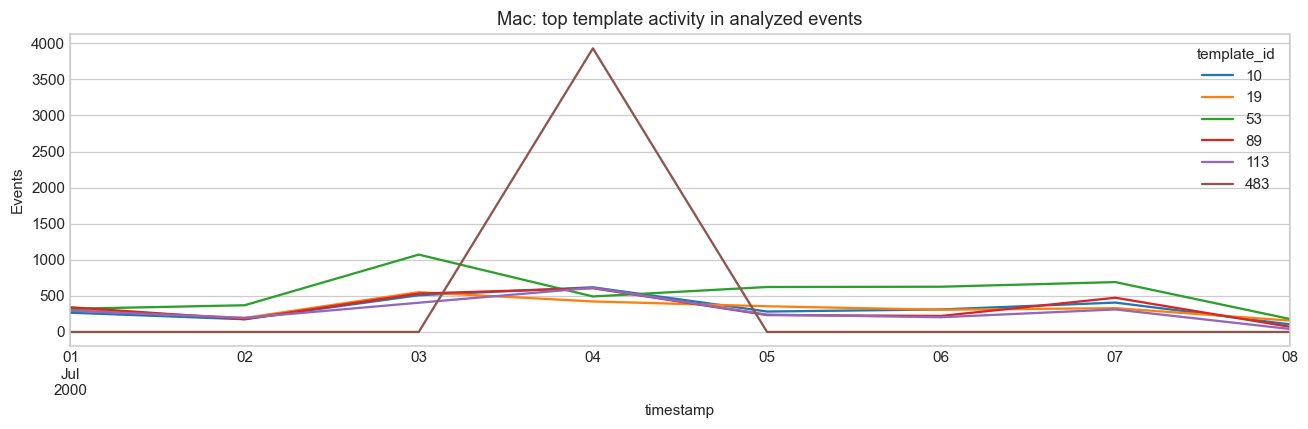

In [11]:
events, templates = mine_templates(events)
assert templates["count"].sum() == len(events)
display({"templates": len(templates), "singleton_templates": int(templates["count"].eq(1).sum())})
display(templates.head(12))
display(templates.sort_values(["count", "template"]).head(12))
display(templates.sort_values("first").head(10))
observation_end = events.timestamp.max()
template_inactivity = templates.assign(days_since_last=(observation_end - templates["last"]).dt.total_seconds() / 86400)
display(template_inactivity.sort_values("days_since_last", ascending=False).head(10))
top_ids = templates.head(6).index
activity = events.loc[events.template_id.isin(top_ids)].groupby([pd.Grouper(key="timestamp", freq="1D"), "template_id"]).size().unstack(fill_value=0)
activity.plot(figsize=(12, 4), title=f"{NAME}: top template activity in analyzed events")
plt.ylabel("Events")
plt.tight_layout()
plt.show()

## 9. Разметка и аномалии

Официальной разметки аномалий нет. Поэтому долю аномалий, длительность размеченных инцидентов, label-exclusive шаблоны и десять размеченных аномалий оценить нельзя. INFO/WARN/ERROR, `Failed password`, выбросы объёма и редкие шаблоны не подменяют ground truth. Ниже читаем десять **подозрительных по тексту примеров**, чтобы предложить будущие правила разметки; это не подтверждённые инциденты.

In [12]:
assert events.is_anomaly.isna().all()
candidates = events.loc[events.message.str.contains(r"error|fail|warn|exception|invalid|broken|timeout", case=False, regex=True)]
with pd.option_context("display.max_colwidth", None):
    display(candidates.drop_duplicates("message").head(10)[["line_no", "timestamp", "component", "message"]])
display({"text_rule_candidate_events": len(candidates), "ground_truth_anomaly_count": "unknown"})

,line_no,timestamp,component,message
29,30,2000-07-01 09:00:55,symptomsd,-[NetworkAnalyticsEngine _writeJournalRecord:fromCellFingerprint:key:atLOI:ofKind:lqm:isFaulty:] Hashing of the primary key failed. Dropping the journal record.
49,50,2000-07-01 09:00:56,mDNSResponder,69: Could not write data to client PID[11203](Mail) because of error - aborting connection
60,61,2000-07-01 09:00:56,Dropbox,[0701/090056:WARNING:dns_config_service_posix.cc(306)] Failed to read DnsConfig.
79,80,2000-07-01 09:00:56,corecaptured,"CCFile::captureLog Received Capture notice id: 1498924856.421273, reason = AssocFail:sts:5_rsn:0"
83,84,2000-07-01 09:00:56,corecaptured,"CCFile::copyFile fileName is [2017-07-01_08,57,48.779252]-io80211Family-002.pcapng, source path:/var/log/CoreCapture/com.apple.iokit.IO80211Family/IO80211AWDLPeerManager//[2017-07-01_08,57,48.779252]-io80211Family-002.pcapng, dest path:/Library/Logs/CrashReporter/CoreCapture/com.apple.iokit.IO80211Family/[2017-07-01_09,00,56.421273]=AssocFail:sts:5_rsn:0/IO80211AWDLPeerManager//[2017-07-01_08,57,48.779252]-io80211Family-002.pcapng"
88,89,2000-07-01 09:00:56,corecaptured,"CCFile::copyFile fileName is [2017-07-01_08,57,48.782711]-CCIOReporter-002.xml, source path:/var/log/CoreCapture/com.apple.iokit.IO80211Family/OneStats//[2017-07-01_08,57,48.782711]-CCIOReporter-002.xml, dest path:/Library/Logs/CrashReporter/CoreCapture/com.apple.iokit.IO80211Family/[2017-07-01_09,00,56.421273]=AssocFail:sts:5_rsn:0/OneStats//[2017-07-01_08,57,48.782711]-CCIOReporter-002.xml"
94,95,2000-07-01 09:00:56,corecaptured,"CCFile::copyFile fileName is [2017-07-01_08,57,48.822257]-AirPortBrcm4360_Logs-002.txt, source path:/var/log/CoreCapture/com.apple.driver.AirPort.Brcm4360.0/DriverLogs//[2017-07-01_08,57,48.822257]-AirPortBrcm4360_Logs-002.txt, dest path:/Library/Logs/CrashReporter/CoreCapture/com.apple.driver.AirPort.Brcm4360.0/[2017-07-01_09,00,56.421273]=AssocFail:sts:5_rsn:0/DriverLogs//[2017-07-01_08,57,48.822257]-AirPortBrcm4360_Logs-002.txt"
98,99,2000-07-01 09:00:57,corecaptured,"doSaveChannels@286: Will write to: /Library/Logs/CrashReporter/CoreCapture/IOReporters/[2017-07-01_09,00,56.421273] - AssocFail:sts:5_rsn:0.xml"
135,136,2000-07-01 09:01:05,CalendarAgent,AOSKit ERROR: XPC CLIENT: Connection [0x7fa11ad29e00] event handler received event with type: [XPC_TYPE_ERROR]. Description: [Connection interrupted]
259,260,2000-07-01 09:02:27,Dropbox,[0701/090227:WARNING:dns_config_service_posix.cc(306)] Failed to read DnsConfig.


{'text_rule_candidate_events': 19655, 'ground_truth_anomaly_count': 'unknown'}

## 10. Временные окна

Сравниваем фиксированные непересекающиеся окна 1, 5, 15, 60 минут и сутки. Сетка покрывает весь наблюдаемый период, нулевые окна сохраняются. Крайние окна частичны. `above_p99` — разведочный индикатор концентрации; p99 не является порогом доказанной аномалии. Дисперсия/среднее описывает неравномерность нагрузки, но без стационарности не служит тестом на аномалии.

Считаем восстановленные события с валидным временем. Для Mac скрытые syslog-повторы не разворачиваем, поэтому это интенсивность опубликованных событий, не всех событий системы.

,windows,empty,empty_fraction,mean,median,p99,max,above_p99,variance_over_mean
window_minutes,,,,,,,,,
1,10075,7113,0.706005,10.634739,0.0,180.26,4016,101,295.665240
5,2016,1012,0.501984,53.147321,0.0,490.75,4051,21,390.928705
15,673,141,0.209510,159.205052,105.0,1308.40,4231,7,453.996362
60,169,19,0.112426,633.994083,514.0,3322.60,5000,2,643.555193
1440,8,0,0.000000,13393.125000,12808.5,21619.86,21809,1,2280.291705


,count,alerts
2000-07-04 23:22:00,4016,NaN
2000-07-05 14:04:00,1619,NaN
2000-07-03 16:07:00,785,NaN
2000-07-07 13:38:00,666,NaN
2000-07-07 13:42:00,620,NaN
2000-07-06 12:03:00,609,NaN
2000-07-05 19:00:00,493,NaN
2000-07-07 13:40:00,466,NaN
2000-07-03 16:27:00,456,NaN
2000-07-02 22:24:00,441,NaN


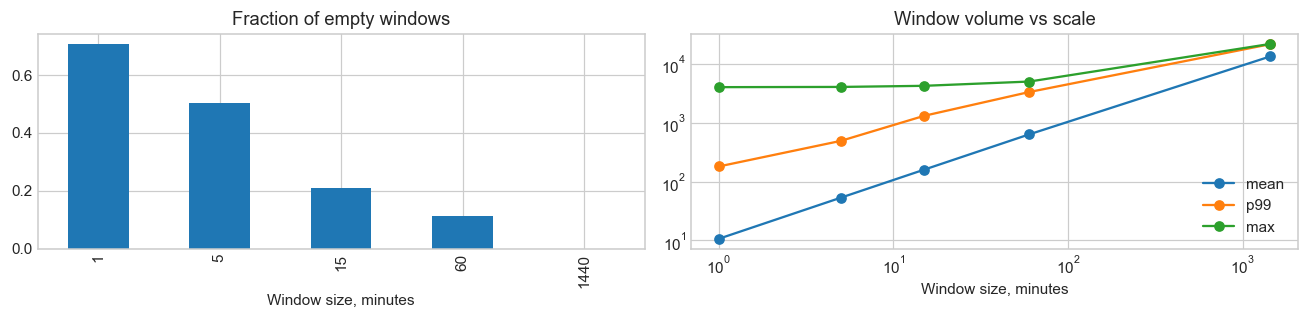

In [13]:
windows = window_summary(minutes)
display(windows)
display(dense.nlargest(10, "count"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
windows.empty_fraction.plot.bar(ax=axes[0], title="Fraction of empty windows")
windows[["mean", "p99", "max"]].plot(ax=axes[1], marker="o", logy=True, logx=True, title="Window volume vs scale")
axes[0].set_xlabel("Window size, minutes")
axes[1].set_xlabel("Window size, minutes")
plt.tight_layout()
plt.show()

## 11. Проверяемый дайджест и открытые вопросы

Следующая ячейка собирает ключевые числа из текущего запуска. В финальной Markdown-ячейке — их интерпретация и ограничения.

In [14]:
digest = {
    "dataset": NAME,
    "physical_lines_full": int(source["physical_lines"]),
    "analyzed_events": len(events),
    "parse_fraction_physical": float(physical.parse_ok.mean()),
    "duplicates_in_analyzed_physical": int(physical.raw.duplicated().sum()),
    "multiline_events": int(events.physical_line_count.gt(1).sum()),
    "start": str(dense.index.min()), "end": str(dense.index.max()),
    "templates": len(templates), "singleton_templates": int(templates["count"].eq(1).sum()),
    "message_length_median": float(events.message_length.median()),
    "empty_minutes_fraction": float(windows.loc[1, "empty_fraction"]),
    "busiest_minute": str(dense["count"].idxmax()),
    "busiest_minute_count": int(dense["count"].max()),
    "top_component": str(events.component.value_counts().index[0]),
    "top_template": str(templates.iloc[0].template),
    "top_template_count": int(templates.iloc[0]["count"]),
    "entity_unique": {k: int(v) for k, v in entities["unique"].items()},
    "session_candidates": len(sessions),
    "unparsed_header_lines": int((physical.header_start & ~physical.parse_ok).sum()),
}

display(JSON(digest))

<IPython.core.display.JSON object>

### Выводы по Mac

- Полный источник: **117,283 физических строк**. Анализ текстов: **107,145 событий**.
- Медиана длины сообщения — **76 символов**. Drain3 выделил **636 шаблонов**, из них **92** встречаются один раз.
- На полной временной сетке **70.60% пустых минут**. Максимум — **4,016 событий/минуту**, 2000-07-04 23:22:00. Крайние окна частичны.

Парсер распознаёт все строки, похожие на заголовок; 10 138 остальных физических строк присоединены к предыдущим заголовкам. Получилось 1 068 многострочных событий. Среди физических строк есть 21 447 повторов сверх первого вхождения, в том числе элементы многострочного текста; это не равно числу дублированных событий.

Наиболее активный компонент — `kernel`, но лог содержит разные приложения. Самый частый шаблон — `last message repeated ...` (4 377 записей): syslog уже подавлял повторы. Поэтому интенсивность опубликованных событий занижает число реальных сообщений, а искусственное разворачивание N повторов создало бы выдуманные timestamps.

В исходном порядке есть 560 инверсий времени; самое раннее событие предшествует первой строке файла. В путях CoreCapture встречаются даты `2017-07-01`, что поддерживает гипотезу о сборе в 2017 году, но заголовок syslog года не содержит. Основная ось оставлена условной, зона неизвестна. Многочасовые пустоты могут быть связаны со сном ноутбука, но это только гипотеза. Различные hostname не означают различные устройства: по описанию источника это один MacBook.

Найдены IP, URL, UUID, пути и кандидаты в устройства/хэши, но общего session ID нет. Десять подозрительных примеров отражают проблемы отдельных приложений и устройств; без разметки нельзя объявить их аномалиями всей системы. Для будущего детектора стоит отдельно моделировать компоненты и состояния активности, учитывать сообщения о сне/пробуждении и подавлении повторов.

**Открытые вопросы:** когда ноутбук спал и менял сеть/hostname; какие ошибки влияли на пользователя; достаточно ли надёжно восстановлены границы многострочных сообщений; сколько событий было подавлено syslog? Редкие шаблоны требуют ручной проверки, а не автоматического присвоения anomaly label.

**Воспроизводимость:** полный архив Zenodo с закреплённым MD5, контроль SHA-256, фиксированный seed, явные правила парсинга, версии библиотек в начале. Подсчёты соответствуют параметрам этого выполненного ноутбука. Все 11 пунктов чеклиста рассмотрены; ограничения разметки и неизвестные поля указаны явно.